# Лабораторная работа №2: Исследовательский анализ данных (EDA)

#### __1. Формулировка бизнес-задачи__

__Цель работы:__ Провести разведочный анализ данных (EDA) для датасета задач Google Borg Cluster, визуализировать распределения признаков, выявить взаимосвязи и сформулировать выводы для дальнейшего моделирования.

#### __1. Загрузка данных и подготовка__

Загрузим очищенный датасет из первой лабораторной работы.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Настройка отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Загрузка данных
df = pd.read_csv('Data\Dataset_1laba.csv', sep = ',', encoding='latin1')

# Настройка стиля графиков
sns.set_theme(style="whitegrid")

#### __2. Построение гистограмм и графиков плотности__

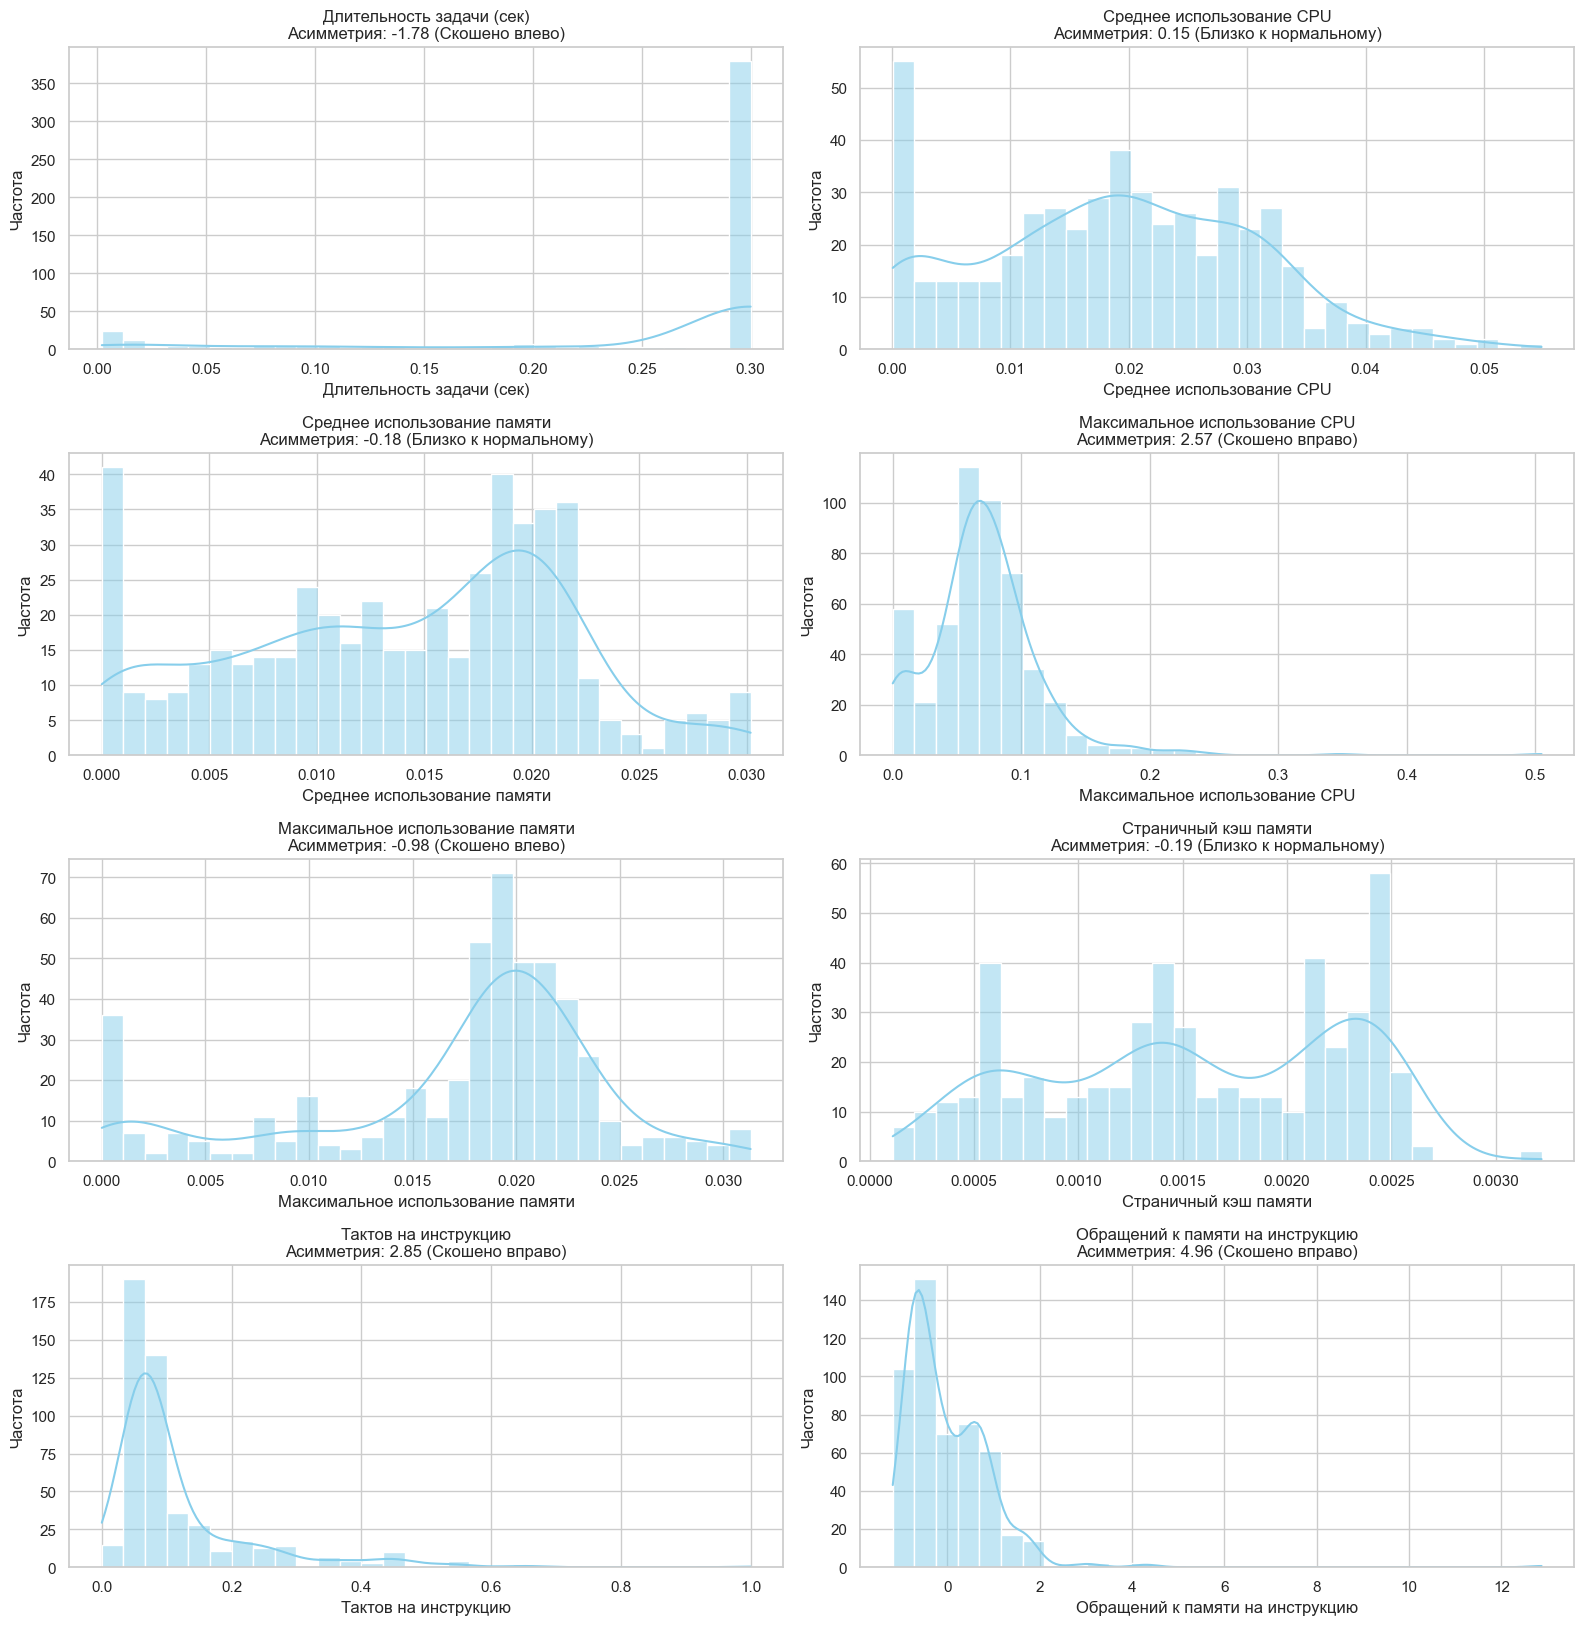

In [3]:
# Основные числовые признаки для анализа
numeric_features = ['duration', 'avg_cpus', 'avg_memory', 'max_cpus', 'max_memory',
                    'page_cache_memory', 'cycles_per_instruction_norm',
                    'memory_accesses_per_instruction_std']

# Русские названия для признаков из датасета
rus_names = {
    'duration': 'Длительность задачи (сек)',
    'avg_cpus': 'Среднее использование CPU',
    'avg_memory': 'Среднее использование памяти',
    'max_cpus': 'Максимальное использование CPU',
    'max_memory': 'Максимальное использование памяти',
    'page_cache_memory': 'Страничный кэш памяти',
    'cycles_per_instruction_norm': 'Тактов на инструкцию',
    'memory_accesses_per_instruction_std': 'Обращений к памяти на инструкцию'
}

# Построение гистограмм
plt.figure(figsize=(16, 20))  
for i, col in enumerate(numeric_features, 1):
    plt.subplot(5, 2, i)  
    
    # Строим график
    sns.histplot(df[col], kde=True, color='skyblue', bins=30)

    # Расчет асимметрии
    skewness = df[col].skew()
    if skewness > 0.5:
        shape = "Скошено вправо"
    elif skewness < -0.5:
        shape = "Скошено влево"
    else:
        shape = "Близко к нормальному"
    
    title_rus = rus_names.get(col, col)
    plt.title(f'{title_rus}\nАсимметрия: {skewness:.2f} ({shape})', fontsize=12)
    plt.xlabel(title_rus)
    plt.ylabel('Частота')

plt.tight_layout()
plt.show()

#### __3. Построение диаграмм «ящик с усами» для определения выбросов__

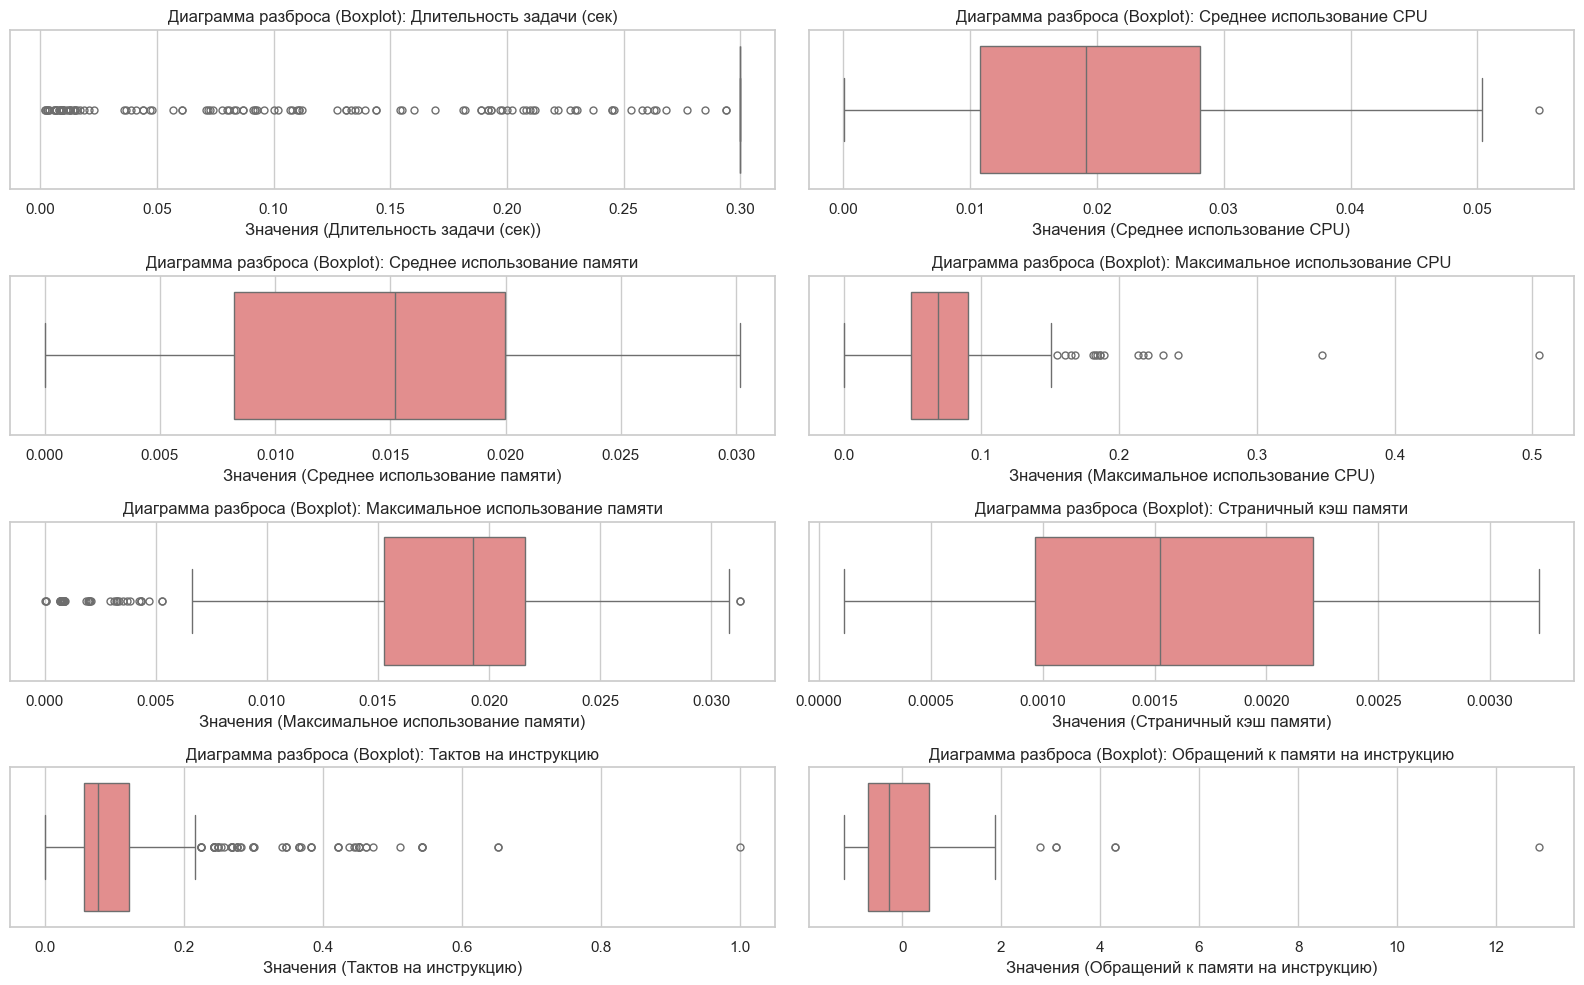

Анализ выбросов:
- duration: обнаружено 121 выбросов (границы: 0.30 - 0.30)
- avg_cpus: обнаружено 1 выбросов (границы: -0.02 - 0.05)
- avg_memory: обнаружено 0 выбросов (границы: -0.01 - 0.04)
- max_cpus: обнаружено 17 выбросов (границы: -0.01 - 0.15)
- max_memory: обнаружено 61 выбросов (границы: 0.01 - 0.03)
- page_cache_memory: обнаружено 0 выбросов (границы: -0.00 - 0.00)
- cycles_per_instruction_norm: обнаружено 65 выбросов (границы: -0.04 - 0.22)
- memory_accesses_per_instruction_std: обнаружено 6 выбросов (границы: -2.54 - 2.39)


In [4]:
# Построение диаграмм «ящик с усами»
plt.figure(figsize=(16, 12))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(5, 2, i)
    # Строим график
    sns.boxplot(x=df[col], color='lightcoral', fliersize=5)
    title_rus = rus_names.get(col, col)
    plt.title(f'Диаграмма разброса (Boxplot): {title_rus}', fontsize=12)
    plt.xlabel(f'Значения ({title_rus})')
plt.tight_layout()
plt.show()

#Вывод статистики по выбросам (метод IQR)
print("Анализ выбросов:")
for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"- {col}: обнаружено {len(outliers)} выбросов (границы: {lower_bound:.2f} - {upper_bound:.2f})")

#### __4. Построение столбчатых диаграмм для каждого категориального признака__


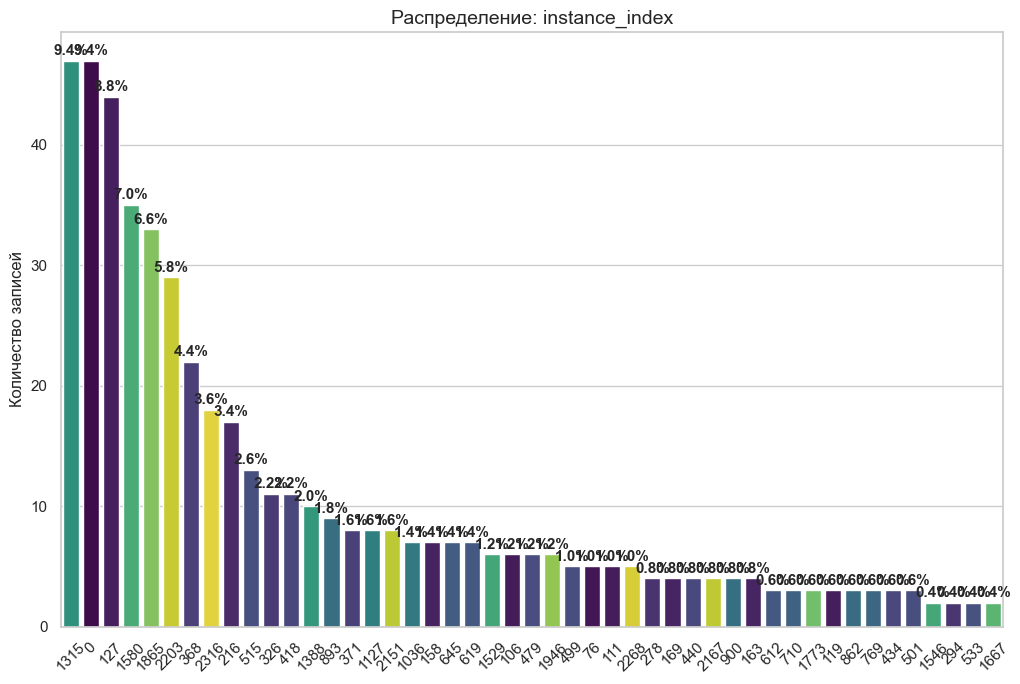


Признак 'instance_index':
- Самая частая категория: 1315 (9.4%)
- Количество уникальных значений: 47


In [5]:
# Основные числовые признаки для анализа
category_features = ['instance_index']

# Создаем сетку графиков (1 строка, 2 колонки)
plt.figure(figsize=(20, 7))
for i, col in enumerate(category_features, 1):
    plt.subplot(1, 2, i)
    order = df[col].value_counts().index
    # Строим график
    ax = sns.countplot(data=df, x=col, order=order, hue=col, palette='viridis', legend=False)

    # Добавляем проценты над каждым столбцом
    total = len(df[col])
    for p in ax.patches:
        percentage = f'{100 * p.get_height() / total:.1f}%'
        x = p.get_x() + p.get_width() / 2
        y = p.get_height() + (max(df[col].value_counts()) * 0.01) # Небольшой отступ сверху
        ax.annotate(percentage, (x, y), ha='center', fontsize=11, fontweight='bold')
    plt.title(f'Распределение: {col}', fontsize=14)
    plt.xticks(rotation=45)
    plt.xlabel('')
    plt.ylabel('Количество записей')
plt.tight_layout()
plt.show()

for col in category_features:
    counts = df[col].value_counts()
    top_cat = counts.idxmax()
    top_perc = (counts.max() / len(df)) * 100
    print(f"\nПризнак '{col}':")
    print(f"- Самая частая категория: {top_cat} ({top_perc:.1f}%)")
    print(f"- Количество уникальных значений: {df[col].nunique()}")

#### __4. Анализ взаимосвязей между признаками__
Построим матрицу корреляции и диаграммы рассеяния для поиска зависимостей.

<Figure size 1200x1000 with 0 Axes>

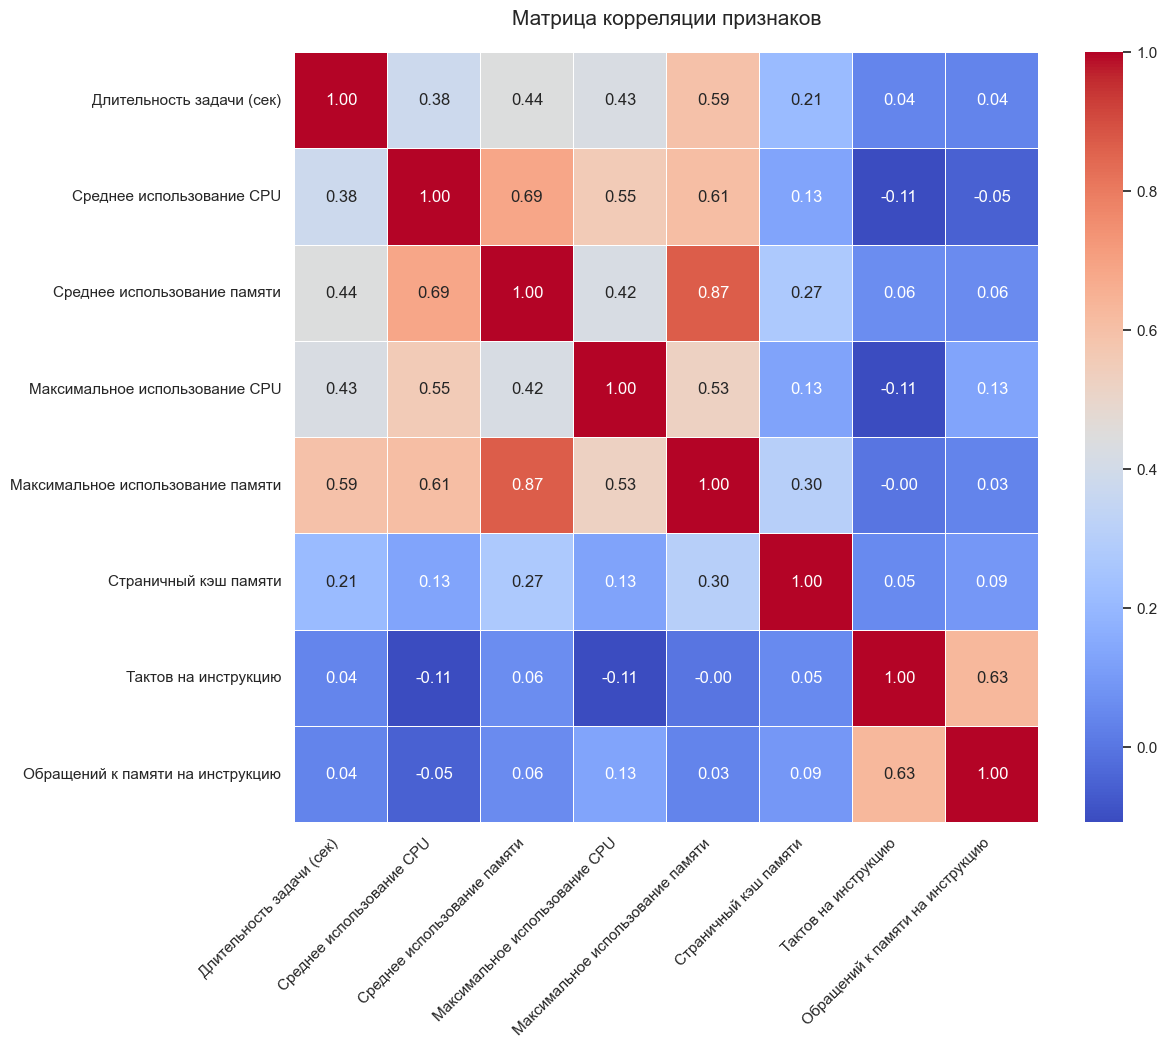

In [6]:
plt.figure(figsize=(12, 10))

numeric_df = df[['duration', 'avg_cpus', 'avg_memory', 'max_cpus', 'max_memory',
                    'page_cache_memory', 'cycles_per_instruction_norm',
                    'memory_accesses_per_instruction_std']]
corr_matrix = numeric_df.corr()

labels_rus = [rus_names.get(col, col) for col in corr_matrix.columns]

#Строим тепловую карту
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, xticklabels=labels_rus, yticklabels=labels_rus)
plt.title('Матрица корреляции признаков', fontsize=15, pad=20)
plt.xticks(rotation=45, ha='right')
plt.show()

#### __5. Определение пар с высокой корреляцией__

In [7]:
# Определение пар с высокой корреляцией
print("Пары признаков с высокой корреляцией (|r| > 0.7):")
corr_unstacked = corr_matrix.unstack().sort_values(ascending=False)
# Убираем корреляцию признака самого с собой (1.0) и дубликаты
high_corr = corr_unstacked[(abs(corr_unstacked) > 0.7) & (abs(corr_unstacked) < 1.0)]
print(high_corr.drop_duplicates())

Пары признаков с высокой корреляцией (|r| > 0.7):
max_memory  avg_memory    0.866938
dtype: float64


#### __6. Диаграммы рассеяния для наиболее коррелированных пар__

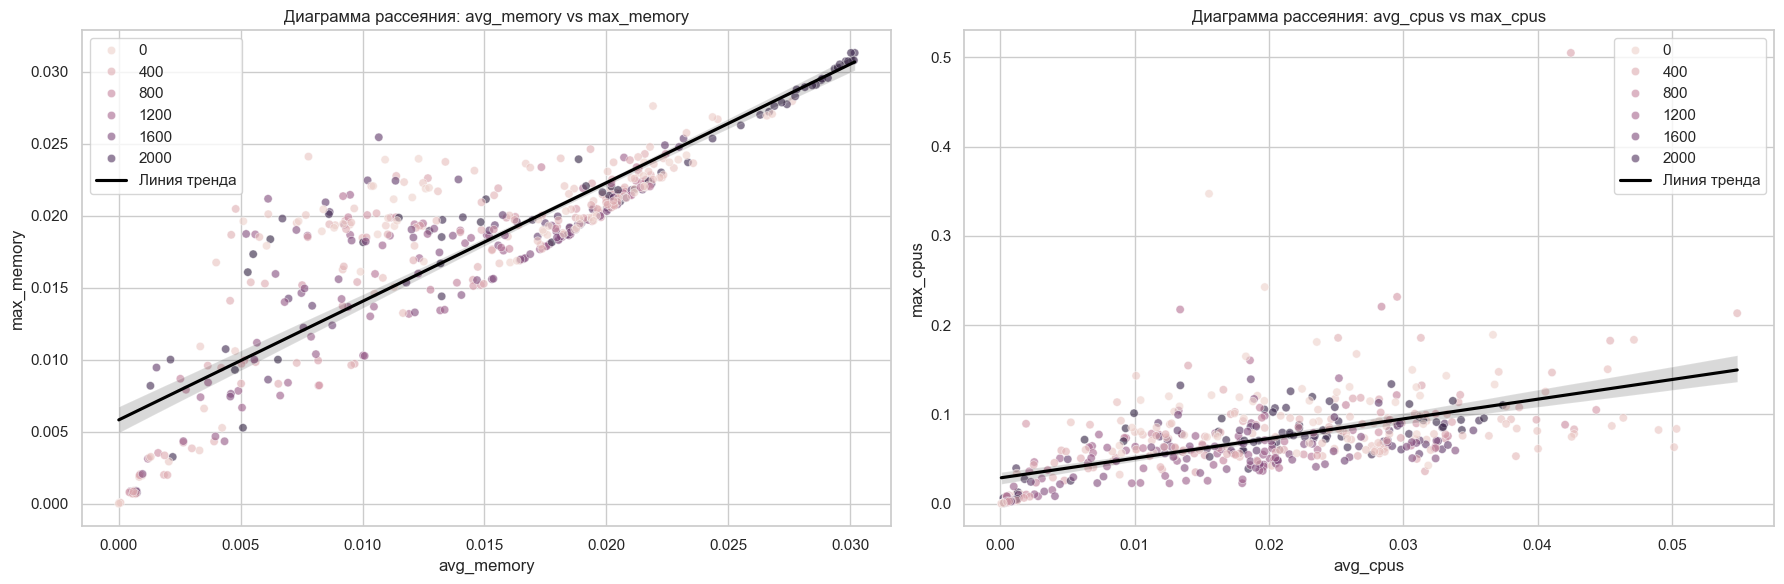

In [8]:
# Диаграммы рассеяния для наиболее коррелированных пар
target_pairs = [
    ('avg_memory', 'max_memory'),
    ('avg_cpus', 'max_cpus', )
]
plt.figure(figsize=(18, 6))

for i, (x_col, y_col) in enumerate(target_pairs, 1):
    plt.subplot(1, 2, i)
    
    sns.scatterplot(data=df, x=x_col, y=y_col, hue='instance_index', alpha=0.6)
    
    sns.regplot(data=df, x=x_col, y=y_col, scatter=False, color='black', label='Линия тренда')
    plt.title(f'Диаграмма рассеяния: {x_col} vs {y_col}')
    plt.legend()
plt.tight_layout()
plt.show()

#### __6. основные выводы на основе проведенного EDA__

Длительность задач (duration): Большинство задач имеют длительность 0.3 секунды, 121 задача (24%) короче – это значительная аномалия в распределении

Использование ресурсов: Все признаки, связанные с потреблением CPU, имеют сильную положительную асимметрию (скошены вправо) – большинство задач потребляют мало ресурсов, но существует небольшое количество "тяжелых" задач

CPI и MAP: Распределение cycles_per_instruction имеет несколько пиков, что указывает на разные режимы работы задач

max_memory: 61 выброс (12.2% данных) – множество задач с аномально высоким пиковым потреблением памяти

cycles_per_instruction: 65 выбросов (13.1% данных) – значительное количество задач с низкой эффективностью использования CPU

max_cpus: 17 выбросов (3.4% данных) – редкие задачи с высоким потреблением CPU

#### __7. Закономерности и аномалии__

Закономерности:
- Ресурсная асимметрия: В кластере преобладают "легкие" задачи с низким потреблением ресурсов. Меньшинство "тяжелых" задач потребляет ресурсы на порядки больше.
- Связь средних и пиковых значений: Существует прямая зависимость между средним и максимальным потреблением ресурсов. Это позволяет прогнозировать пиковые нагрузки на основе средних показателей.
- Связь CPU и памяти: Умеренная положительная корреляция (r ~ 0.46) указывает, что задачи, интенсивно использующие CPU, также требуют больше памяти.

Аномалии:
- Длительность задач: 121 задача имеет длительность меньше 0.3 секунды, при этом основная масса задач длится ровно 0.3 секунды. Это указывает на существование двух классов задач: "стандартные" (0.3 сек) и "короткие" (<0.3 сек).
- Пиковое использование памяти: 61 задача имеет аномально высокое пиковое потребление памяти (>0.03). Память оказалась более "горячим" ресурсом, чем CPU.

Взаимосвязи:
- Сильная связь между средним и максимальным потреблением для памяти (r=0.87). умеренная связь для CPU (r=0.61). Использование обоих признаков (средняя памяти и средняя cpu) в модели избыточно

#### __8. Гипотезы для дальнейшего исследования__

- __Взаимосвязь длительности и пикового потребления:__ Короткие задачи (длительностью < 0.3 сек) имеют более высокие пиковые значения потребления CPU и памяти по сравнению с длительными задачами, так как они концентрируют всю нагрузку в короткий промежуток времени.
- __Прогнозирование "проблемных" задач:__ Задачи, являющиеся выбросами по одному ресурсу (например, память), с высокой вероятностью будут выбросами и по другому ресурсу, что позволяет построить модель раннего предупреждения о "проблемных" задачах.
- __Влияние страничного кэша на эффективность:__ Задачи с высоким значением page_cache_memory имеют более низкий CPI (выше эффективность), так как данные уже находятся в кэше и не требуют дорогостоящих обращений к основной памяти.



In [9]:
new_columns = [
    'duration',                             # Длительность задачи (сек)
    'instance_index',                       # Индекс задачи в коллекции
    'avg_cpus',                              # Среднее использование CPU
    'avg_memory',                            # Среднее использование памяти
    'max_cpus',                             # Максимальное использование CPU
    'max_memory',                           # Максимальное использование памяти
    'page_cache_memory',                    # Страничный кэш памяти
    'cycles_per_instruction_norm',          # Тактов на инструкцию
    'memory_accesses_per_instruction_std'   # Обращений к памяти на инструкцию
]

df_cleaned = df[new_columns].copy()

# Сохраняем
df_cleaned.to_csv("Data/Dataset_2laba.csv", index=False)
print(f"Создан новый датасет: Data/Dataset_2laba.csv")
print(f"Размер нового файла: {df_cleaned.shape[0]} строк и {df_cleaned.shape[1]} колонок")

Создан новый датасет: Data/Dataset_2laba.csv
Размер нового файла: 498 строк и 9 колонок
